In [109]:
import numpy as np
import pandas as pd 
import re
from bs4 import BeautifulSoup
from keras.preprocessing.text import Tokenizer
from keras.utils import pad_sequences
from nltk.corpus import stopwords
from tensorflow.keras.layers import Input, LSTM, Embedding, Dense, Concatenate, TimeDistributed
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
import warnings
from tensorflow.keras.layers import Attention

In [110]:
data = pd.read_csv(r'D:\projec_ds\data\summary_extractive_sbert_eval.csv')
data.head()

,title,content,extractive_summary
0,Bộ trưởng Giao thông Mỹ tuyên bố cải cách FAA ...,"Thông tin trên tài khoản mạng xã hội X, Bộ trư...","Thông tin trên tài khoản mạng xã hội X, Bộ trư..."
1,Cao tốc Pháp Vân - Cầu Giẽ ùn ứ kéo dài chiều ...,Theo ghi nhận của PV Báo Giao thông trong chiề...,"Thời điểm 15 giờ chiều nay, hàng dài ô tô nối ..."
2,Tai nạn giao thông làm 33 người tử vong ngày m...,"Chiều 31/1, đại diện Cục CSGT (Bộ Công an) cho...","Về xử lý vi phạm, lực lượng chức năng cả nước ..."
3,Du xuân Đà Lạt bằng tàu cổ có gì hấp dẫn?,"Chi nhánh Vận tải đường sắt Sài Gòn cho biết, ...","Chi nhánh Vận tải đường sắt Sài Gòn cho biết, ..."
4,Hơn 4.800 tài xế vi phạm giao thông ngày Mùng ...,"Ảnh minh họa. Ngày 31/1, Cục CSGT - Bộ Công an...","Cũng trong ngày, lực lượng chức năng đã kiểm t..."


In [111]:
import pandas as pd

# Giả sử data là DataFrame của bạn
data = data.rename(columns={'content': 'Text', 'extractive_summary': 'Summary'})

# Kiểm tra lại
print(data.head())


                                               title  \
0  Bộ trưởng Giao thông Mỹ tuyên bố cải cách FAA ...   
1  Cao tốc Pháp Vân - Cầu Giẽ ùn ứ kéo dài chiều ...   
2  Tai nạn giao thông làm 33 người tử vong ngày m...   
3          Du xuân Đà Lạt bằng tàu cổ có gì hấp dẫn?   
4  Hơn 4.800 tài xế vi phạm giao thông ngày Mùng ...   

                                                Text  \
0  Thông tin trên tài khoản mạng xã hội X, Bộ trư...   
1  Theo ghi nhận của PV Báo Giao thông trong chiề...   
2  Chiều 31/1, đại diện Cục CSGT (Bộ Công an) cho...   
3  Chi nhánh Vận tải đường sắt Sài Gòn cho biết, ...   
4  Ảnh minh họa. Ngày 31/1, Cục CSGT - Bộ Công an...   

                                             Summary  
0  Thông tin trên tài khoản mạng xã hội X, Bộ trư...  
1  Thời điểm 15 giờ chiều nay, hàng dài ô tô nối ...  
2  Về xử lý vi phạm, lực lượng chức năng cả nước ...  
3  Chi nhánh Vận tải đường sắt Sài Gòn cho biết, ...  
4  Cũng trong ngày, lực lượng chức năng đã kiểm t..

In [112]:
data

,title,Text,Summary
0,Bộ trưởng Giao thông Mỹ tuyên bố cải cách FAA ...,"Thông tin trên tài khoản mạng xã hội X, Bộ trư...","Thông tin trên tài khoản mạng xã hội X, Bộ trư..."
1,Cao tốc Pháp Vân - Cầu Giẽ ùn ứ kéo dài chiều ...,Theo ghi nhận của PV Báo Giao thông trong chiề...,"Thời điểm 15 giờ chiều nay, hàng dài ô tô nối ..."
2,Tai nạn giao thông làm 33 người tử vong ngày m...,"Chiều 31/1, đại diện Cục CSGT (Bộ Công an) cho...","Về xử lý vi phạm, lực lượng chức năng cả nước ..."
3,Du xuân Đà Lạt bằng tàu cổ có gì hấp dẫn?,"Chi nhánh Vận tải đường sắt Sài Gòn cho biết, ...","Chi nhánh Vận tải đường sắt Sài Gòn cho biết, ..."
4,Hơn 4.800 tài xế vi phạm giao thông ngày Mùng ...,"Ảnh minh họa. Ngày 31/1, Cục CSGT - Bộ Công an...","Cũng trong ngày, lực lượng chức năng đã kiểm t..."
...,...,...,...
2905,Truy tìm tài xế ô tô tải bỏ chạy sau va chạm x...,"Chiều 20/8, Công an xã Bình Mỹ, TP.HCM đang tr...","Chiều 20/8, Công an xã Bình Mỹ, TP.HCM đang tr..."
2906,"Xe container va chạm xe máy, cụ ông 76 tuổi tử...","Khoảng 8h30 ngày 20/8, xe container biển số 50...","Khoảng 8h30 ngày 20/8, xe container biển số 50..."
2907,'Thót tim' xe ôm công nghệ phóng ngược chiều t...,Mạng xã hội mới đây xuất hiện một đoạn video g...,Mạng xã hội mới đây xuất hiện một đoạn video g...
2908,"Tạm ngưng lưu thông ôtô qua cầu Bình Triệu 1, ...","TPO - Bắt đầu từ 16 giờ 40 ngày 26/8, xe ô tô ...","TPO - Bắt đầu từ 16 giờ 40 ngày 26/8, xe ô tô ..."


In [113]:
stop_words = set(stopwords.words('english')) 

def text_cleaner(text,num):
    # lower
    newString = text.lower()
    # remove HTML
    newString = BeautifulSoup(newString, "lxml").text
    # Remove any text inside the parenthesis
    newString = re.sub(r'\([^)]*\)', '', newString)
    # remove double quotes
    newString = re.sub('"','', newString)
    # remove 's
    newString = re.sub(r"'s\b","",newString)
    # Eliminate punctuations and special characters
    #newString = re.sub("[^a-zA-Z]", " ", newString)
    # Remove stopwords
    if(num==0):
        tokens = [w for w in newString.split() if not w in stop_words]
    else:
        tokens=newString.split()
    long_words=[]
    # Remove short words
    for i in tokens:
        if len(i)>1:                                                 
            long_words.append(i)   
    return (" ".join(long_words)).strip()

In [114]:
cleaned_text = []
for t in data['Text']:
    cleaned_text.append(text_cleaner(t,0))

In [115]:
cleaned_text[:2]  

['thông tin trên tài khoản mạng xã hội x, bộ trưởng giao thông mỹ sean duffy khẳng định: hiện đang trong quá trình xây dựng kế hoạch cải cách faa. tôi hy vọng sẽ sớm công bố kế hoạch này. trước đó, khi hay tin về vụ tai nạn thảm khốc thời điểm máy bay dân dụng của hãng hàng không american airlines và máy bay quân sự black hawk khi đang đến gần sân bay quốc gia ronald reagan washington và rơi xuống sông potomac ngày 30/1 theo giờ địa phương khiến 67 người thiệt mạng, tổng thống mỹ donald trump chỉ trích gay gắt những nỗ lực đa dạng hóa của faa đồng thời chỉ đạo lập tức có đánh giá về toàn hàng không. bộ trưởng giao thông mỹ sean duffy phát biểu trước báo giới theo ông trump, những nỗ lực thúc đẩy sự đa dạng tại faa có thể là nguyên nhân gây ra vụ tai nạn. tại cuộc họp báo nhà trắng, ông trump chỉ trích gay gắt bộ trưởng bộ giao thông pete buttigieg dưới thời tổng thống joe biden là thảm họa, phá hỏng mọi thứ chỉ vì đa dạng. faa đang thiếu khoảng 3.000 nhân viên kiểm soát không lưu với m

In [116]:
cleaned_summary = []
for t in data['Summary']:
    cleaned_summary.append(text_cleaner(t,1))

In [117]:
data['cleaned_text']=cleaned_text
data['cleaned_summary']=cleaned_summary

In [118]:
data.head()

,title,Text,Summary,cleaned_text,cleaned_summary
0,Bộ trưởng Giao thông Mỹ tuyên bố cải cách FAA ...,"Thông tin trên tài khoản mạng xã hội X, Bộ trư...","Thông tin trên tài khoản mạng xã hội X, Bộ trư...","thông tin trên tài khoản mạng xã hội x, bộ trư...","thông tin trên tài khoản mạng xã hội x, bộ trư..."
1,Cao tốc Pháp Vân - Cầu Giẽ ùn ứ kéo dài chiều ...,Theo ghi nhận của PV Báo Giao thông trong chiề...,"Thời điểm 15 giờ chiều nay, hàng dài ô tô nối ...",theo ghi nhận của pv báo giao thông trong chiề...,"thời điểm 15 giờ chiều nay, hàng dài tô nối đu..."
2,Tai nạn giao thông làm 33 người tử vong ngày m...,"Chiều 31/1, đại diện Cục CSGT (Bộ Công an) cho...","Về xử lý vi phạm, lực lượng chức năng cả nước ...","chiều 31/1, đại diện cục csgt cho biết, trong ...","về xử lý vi phạm, lực lượng chức năng cả nước ..."
3,Du xuân Đà Lạt bằng tàu cổ có gì hấp dẫn?,"Chi nhánh Vận tải đường sắt Sài Gòn cho biết, ...","Chi nhánh Vận tải đường sắt Sài Gòn cho biết, ...","chi nhánh vận tải đường sắt sài gòn cho biết, ...","chi nhánh vận tải đường sắt sài gòn cho biết, ..."
4,Hơn 4.800 tài xế vi phạm giao thông ngày Mùng ...,"Ảnh minh họa. Ngày 31/1, Cục CSGT - Bộ Công an...","Cũng trong ngày, lực lượng chức năng đã kiểm t...","ảnh minh họa. ngày 31/1, cục csgt bộ công cho ...","cũng trong ngày, lực lượng chức năng đã kiểm t..."


In [119]:
data.replace('', np.nan, inplace=True)
data.dropna(axis=0,inplace=True)

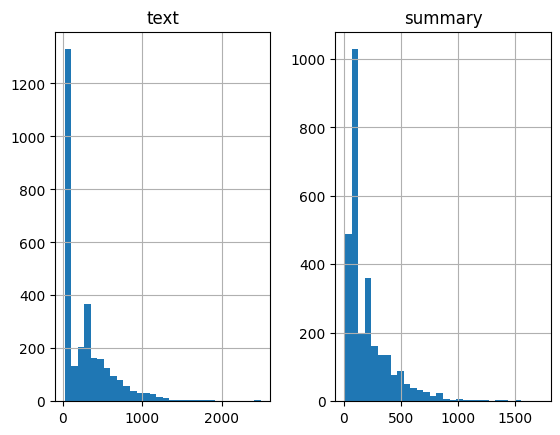

In [120]:
import matplotlib.pyplot as plt

text_word_count = []
summary_word_count = []

# populate the lists with sentence lengths
for i in data['cleaned_text']:
      text_word_count.append(len(i.split()))

for i in data['cleaned_summary']:
      summary_word_count.append(len(i.split()))

length_df = pd.DataFrame({'text':text_word_count, 'summary':summary_word_count})

length_df.hist(bins = 30)
plt.show()

In [121]:
cnt=0
for i in data['cleaned_summary']:
    if(len(i.split()) <= 500):
        cnt=cnt+1
print(cnt/len(data['cleaned_summary']))

0.9003436426116839


In [122]:
cnt=0
for i in data['cleaned_text']:
    if(len(i.split()) <= 300):
        cnt=cnt+1
print(cnt/len(data['cleaned_text']))

0.5917525773195876


In [123]:
max_text_len=400
max_summary_len= 400


In [124]:
cleaned_text =np.array(data['cleaned_text'])
cleaned_summary=np.array(data['cleaned_summary'])

short_text=[]
short_summary=[]

for i in range(len(cleaned_text)):
    if(len(cleaned_summary[i].split())<=max_summary_len and len(cleaned_text[i].split())<=max_text_len):
        short_text.append(cleaned_text[i])
        short_summary.append(cleaned_summary[i])
        
df=pd.DataFrame({'text':short_text,'summary':short_summary}) # new dataframe to use

In [125]:
df['summary'] = df['summary'].apply(lambda x : 'sostok '+ x + ' eostok')
df.head(5)

,text,summary
0,theo ghi nhận của pv báo giao thông trong chiề...,"sostok thời điểm 15 giờ chiều nay, hàng dài tô..."
1,tình huống được cho là diễn ra vào ngày 2/10 t...,"sostok đó là dạng vạch đơn, nét liền, dùng để ..."
2,công ty tnhh mtv đường sắt đô thị số cho biết ...,sostok công ty tnhh mtv đường sắt đô thị số ch...
3,"vào mùa mưa bão, một số thành phố lớn của việt...","sostok trước tình hình này, nhiều người dùng x..."
4,tình huống diễn ra vào khoảng gần giờ sáng 29/...,"sostok tô đi ngược chiều vào đường cao tốc, tà..."


In [126]:
df['summary'][0]

'sostok thời điểm 15 giờ chiều nay, hàng dài tô nối đuôi nhau di chuyển chậm trên cao tốc pháp vân cầu giẽ hướng vào trung tâm tp hà nội. ùn hàng km khiến nhiều phương tiện đi vào làn dừng khẩn cấp bất chấp quy định cấm. cảnh đối lập giữa hướng về trung tâm hà nội và hướng đi các tỉnh phía nam trên cao tốc pháp vân cầu giẽ. lực lượng chức năng đã có mặt từ sớm trên cao tốc pháp vân cầu giẽ để phân làn cho các phương tiện. đường vành đai lúc cuối giờ chiều, xe cộ cũng tăng vọt theo hướng vào trung tâm hà nội. eostok'

In [127]:
df['text'][0]

'theo ghi nhận của pv báo giao thông trong chiều 31/1 lưu lượng phương tiện tại cửa ngõ phía nam thủ đô tăng cao và xuất hiện tình trạng ùn ứ. thời điểm 15 giờ chiều nay, hàng dài tô nối đuôi nhau di chuyển chậm trên cao tốc pháp vân cầu giẽ hướng vào trung tâm tp hà nội. ùn hàng km khiến nhiều phương tiện đi vào làn dừng khẩn cấp bất chấp quy định cấm. dù chưa hết kỳ nghỉ tết nguyên đán ất tỵ 2025 nhưng nhiều người đã chủ động trở lại thủ đô sớm. cảnh đối lập giữa hướng về trung tâm hà nội và hướng đi các tỉnh phía nam trên cao tốc pháp vân cầu giẽ. lực lượng chức năng đã có mặt từ sớm trên cao tốc pháp vân cầu giẽ để phân làn cho các phương tiện. hình ảnh chiến sĩ csgt căng mình làm nhiệm vụ, đảm bảo người dân đi lại toàn, thuận tiện. đường vành đai lúc cuối giờ chiều, xe cộ cũng tăng vọt theo hướng vào trung tâm hà nội. dự báo trong những ngày tới, lưu lượng phương tiện tại các cửa ngõ của hà nội sẽ tăng cao người dân trở lại để bắt đầu làm việc vào ngày mùng tết.'

In [128]:
from sklearn.model_selection import train_test_split

x_tr,x_val,y_tr,y_val=train_test_split(np.array(df['text']), np.array(df['summary']),
                                       test_size=0.1, random_state=0, shuffle=True) 

# A tokenizer builds the vocabulary and converts a word sequence to an integer sequence.
# We will now build tokenizers for text and summary.

x_tokenizer = Tokenizer() 
x_tokenizer.fit_on_texts(list(x_tr))

In [129]:
thresh=4

cnt=0
tot_cnt=0
freq=0
tot_freq=0

for key,value in x_tokenizer.word_counts.items():
    tot_cnt=tot_cnt+1
    tot_freq=tot_freq+value
    if(value<thresh):
        cnt=cnt+1
        freq=freq+value
    
print("% of rare words in vocabulary:", (cnt/tot_cnt)*100)
print("Total Coverage of rare words:", (freq/tot_freq)*100)

% of rare words in vocabulary: 54.12664532194948
Total Coverage of rare words: 1.4608504577287575


In [130]:
print(cnt),print(tot_cnt)

3043
5622


(None, None)

In [131]:
# prepare a tokenizer for reviews on training data

x_tokenizer = Tokenizer(num_words=tot_cnt-cnt) # num_words: the maximum number of words to keep, based on word frequency.
x_tokenizer.fit_on_texts(list(x_tr))

#convert text sequences into integer sequences
x_tr_seq    =   x_tokenizer.texts_to_sequences(x_tr) 
x_val_seq   =   x_tokenizer.texts_to_sequences(x_val)

#padding zero upto maximum length
x_tr    =   pad_sequences(x_tr_seq,  maxlen=max_text_len, padding='post')
x_val   =   pad_sequences(x_val_seq, maxlen=max_text_len, padding='post')

#size of vocabulary ( +1 for padding token)
x_voc   =  x_tokenizer.num_words + 1

In [132]:
x_voc

2580

In [133]:
y_tokenizer = Tokenizer()   
y_tokenizer.fit_on_texts(list(y_tr))

In [134]:
thresh=6

cnt=0
tot_cnt=0
freq=0
tot_freq=0

for key,value in y_tokenizer.word_counts.items():
    tot_cnt=tot_cnt+1
    tot_freq=tot_freq+value
    if(value<thresh):
        cnt=cnt+1
        freq=freq+value
    
print("% of rare words in vocabulary:",(cnt/tot_cnt)*100)
print("Total Coverage of rare words:",(freq/tot_freq)*100)

% of rare words in vocabulary: 60.716441940028176
Total Coverage of rare words: 2.4738910261981766


In [135]:
print(cnt),print(tot_cnt)


3017
4969


(None, None)

In [136]:
print(freq),print(tot_freq)


5408
218603


(None, None)

In [137]:
#prepare a tokenizer for reviews on training data
y_tokenizer = Tokenizer(num_words=tot_cnt-cnt) 
y_tokenizer.fit_on_texts(list(y_tr))

#convert text sequences into integer sequences
y_tr_seq    =   y_tokenizer.texts_to_sequences(y_tr) 
y_val_seq   =   y_tokenizer.texts_to_sequences(y_val) 

#padding zero upto maximum length
y_tr    =   pad_sequences(y_tr_seq, maxlen=max_summary_len, padding='post')
y_val   =   pad_sequences(y_val_seq, maxlen=max_summary_len, padding='post')

#size of vocabulary
y_voc  =   y_tokenizer.num_words +1

In [138]:
ind=[]
for i in range(len(y_tr)):
    cnt=0
    for j in y_tr[i]:
        if j!=0:
            cnt=cnt+1
    if(cnt==2):
        ind.append(i)

y_tr=np.delete(y_tr,ind, axis=0)
x_tr=np.delete(x_tr,ind, axis=0)

In [139]:
ind=[]
for i in range(len(y_val)):
    cnt=0
    for j in y_val[i]:
        if j!=0:
            cnt=cnt+1
    if(cnt==2):
        ind.append(i)

y_val=np.delete(y_val,ind, axis=0)
x_val=np.delete(x_val,ind, axis=0)

In [140]:
latent_dim = 300
embedding_dim=100

# Encoder
encoder_inputs = Input(shape=(max_text_len,))

#embedding layer
enc_emb =  Embedding(x_voc, embedding_dim,trainable=True)(encoder_inputs)

#encoder lstm 1
encoder_lstm1 = LSTM(latent_dim,return_sequences=True,return_state=True,dropout=0.4,recurrent_dropout=0.4)
encoder_output1, state_h1, state_c1 = encoder_lstm1(enc_emb)

#encoder lstm 2
encoder_lstm2 = LSTM(latent_dim,return_sequences=True,return_state=True,dropout=0.4,recurrent_dropout=0.4)
encoder_output2, state_h2, state_c2 = encoder_lstm2(encoder_output1)

#encoder lstm 3
encoder_lstm3=LSTM(latent_dim, return_state=True, return_sequences=True,dropout=0.4,recurrent_dropout=0.4)
encoder_outputs, state_h, state_c= encoder_lstm3(encoder_output2)

# Set up the decoder, using `encoder_states` as initial state.
decoder_inputs = Input(shape=(None,))

#embedding layer
dec_emb_layer = Embedding(y_voc, embedding_dim,trainable=True)
dec_emb = dec_emb_layer(decoder_inputs)

decoder_lstm = LSTM(latent_dim, return_sequences=True, return_state=True,dropout=0.4,recurrent_dropout=0.2)
decoder_outputs,decoder_fwd_state, decoder_back_state = decoder_lstm(dec_emb,initial_state=[state_h, state_c])

# Attention layer
attn_layer = Attention(name='attention_layer')
attn_out= attn_layer([encoder_outputs, decoder_outputs])

# Concat attention input and decoder LSTM output
decoder_concat_input = Concatenate(axis=-1, name='concat_layer')([decoder_outputs, attn_out])

#dense layer
decoder_dense =  TimeDistributed(Dense(y_voc, activation='softmax'))
decoder_outputs = decoder_dense(decoder_concat_input)

# Define the model 
model = Model([encoder_inputs, decoder_inputs], decoder_outputs)

model.summary()

Model: "model_2"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_5 (InputLayer)           [(None, 400)]        0           []                               
                                                                                                  
 embedding_4 (Embedding)        (None, 400, 100)     258000      ['input_5[0][0]']                
                                                                                                  
 lstm_8 (LSTM)                  [(None, 400, 300),   481200      ['embedding_4[0][0]']            
                                 (None, 300),                                                     
                                 (None, 300)]                                                     
                                                                                            

In [141]:
model.compile(optimizer='rmsprop', loss='sparse_categorical_crossentropy')

In [142]:
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1,patience=2)

In [143]:
print(es)

In [144]:
print([x_tr, y_tr[:,:-1]])

[array([[ 158,   99,  900, ...,    0,    0,    0],
       [ 132,  124,  296, ...,    0,    0,    0],
       [ 308,   78,  127, ...,    0,    0,    0],
       ...,
       [  58,   87,    6, ...,    0,    0,    0],
       [ 188,  211, 1360, ...,    0,    0,    0],
       [   8,  651,  398, ...,    0,    0,    0]]), array([[  6, 151,  90, ...,   0,   0,   0],
       [  6, 129, 124, ...,   0,   0,   0],
       [  6, 298,  69, ...,   0,   0,   0],
       ...,
       [  6,  78, 116, ...,   0,   0,   0],
       [  6, 235, 177, ...,   0,   0,   0],
       [  6,  10, 663, ...,   0,   0,   0]])]


In [145]:
print(x_tr[2].shape)

(400,)


In [146]:
y_tr.shape[0]

1918

In [147]:
print(y_tr.reshape(y_tr.shape[0], y_tr.shape[1], 1)[:,1:].shape)

(1918, 399, 1)


In [148]:
print(x_tr.shape)

(1918, 400)


In [149]:
print(y_tr.shape)

(1918, 400)


In [150]:
print(y_tr.reshape(y_tr.shape[0], y_tr.shape[1],1).shape)

(1918, 400, 1)


In [ ]:
history=model.fit([x_tr,y_tr],
                  y_tr,
                  epochs=50,
                  callbacks=[es],
                  batch_size= 64,
                  validation_data=([x_val,y_val], y_val)
                 )

In [ ]:
from matplotlib import pyplot
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='test')
pyplot.legend()
pyplot.show()

In [ ]:
reverse_target_word_index=y_tokenizer.index_word
reverse_source_word_index=x_tokenizer.index_word
target_word_index=y_tokenizer.word_index

In [ ]:
# Encode the input sequence to get the feature vector
encoder_model = Model(inputs=encoder_inputs, outputs=[encoder_outputs, state_h, state_c])

# Decoder setup
# Below tensors will hold the states of the previous time step
decoder_state_input_h = Input(shape=(latent_dim,))
decoder_state_input_c = Input(shape=(latent_dim,))
decoder_hidden_state_input = Input(shape=(max_text_len,latent_dim))

# Get the embeddings of the decoder sequence
dec_emb2= dec_emb_layer(decoder_inputs)
# To predict the next word in the sequence, set the initial states to the states from the previous time step
decoder_outputs2, state_h2, state_c2 = decoder_lstm(dec_emb2, initial_state=[decoder_state_input_h, decoder_state_input_c])

#attention inference
attn_out_inf= attn_layer([decoder_hidden_state_input, decoder_outputs2])
decoder_inf_concat = Concatenate(axis=-1, name='concat')([decoder_outputs2, attn_out_inf])

# A dense softmax layer to generate prob dist. over the target vocabulary
decoder_outputs2 = decoder_dense(decoder_inf_concat)

# Final decoder model
decoder_model = Model(
    [decoder_inputs] + [decoder_hidden_state_input,decoder_state_input_h, decoder_state_input_c],
    [decoder_outputs2] + [state_h2, state_c2])

In [ ]:
def decode_sequence(input_seq):
    # Encode the input as state vectors.
    e_out, e_h, e_c = encoder_model.predict(input_seq)
    print("end")

    # Generate empty target sequence of length 1.
    target_seq = np.zeros((1,1))
    # Populate the first word of target sequence with the start word.
    target_seq[0,0] = target_word_index['sostok']

    stop_condition = False
    decoded_sentence = ''
    while not stop_condition:
        print("start0")
        output_tokens, h, c = decoder_model.predict([target_seq] + [e_out, e_h, e_c])
        print("start")
        # Sample a token
        print(output_tokens[0, -1, :].shape)
        sampled_token_index = np.argmax(output_tokens[0, -1, :])
        sampled_token = reverse_target_word_index[sampled_token_index]
        print("start2")
        if(sampled_token!='eostok'):
            decoded_sentence += ' '+sampled_token

        # Exit condition: either hit max length or find stop word.
        if (sampled_token == 'eostok'  or len(decoded_sentence.split()) >= (max_summary_len-1)):
            stop_condition = True

        # Update the target sequence (of length 1).
        target_seq = np.zeros((1,1))
        target_seq[0] = sampled_token_index

        # Update internal states
        e_h, e_c = h, c
        print("end2")
    return decoded_sentence

In [ ]:
def seq2summary(input_seq):
    newString=''
    for i in input_seq:
        if((i!=0 and i!=target_word_index['sostok']) and i!=target_word_index['eostok']):
            newString=newString+reverse_target_word_index[i]+' '
    return newString

def seq2text(input_seq):
    newString=''
    for i in input_seq:
        if(i!=0):
            newString=newString+reverse_source_word_index[i]+' '
    return newString

In [ ]:
print(x_tr[1].shape)

In [ ]:
print(np.array([x_tr,y_tr]).shape)

In [ ]:
print("Input shape:", x_tr[1].shape)
print("Target shape:", y_tr[1].shape)

In [ ]:
for i in range(0, 10,10):
    print("Review:",seq2text(x_tr[i]))
    print("Original summary:",seq2summary(y_tr[i]))
    test = x_tr[i].reshape(1,max_text_len)
    test = np.tile(test, (max_text_len,1))
    print(test.shape)
    print("Predicted summary:",decode_sequence(test))
    print("\n")